# Loan Default Prediction

### PROBLEM STATEMENT

Lending institutions face significant financial risk when borrowers fail to repay loans as agreed. Identifying high-risk borrowers before approving a loan is critical for minimizing losses while still extending credit to creditworthy customers.

This project predicts whether a borrower will become seriously delinquent (90+ days late) within a 2 year period, based on their credit history, income, debt levels, and personal financial characteristics.

The goal is a reliable classification model that identifies high-risk borrowers while accounting for the natural class imbalance in loan default data, where the vast majority of borrowers do not default.

### OBJECTIVES

1. Develop a classification model to predict loan default risk.
2. Handle class imbalance with SMOTE
3. Evaluate with Precision, Recall, F1 and ROC-AUC  instead of accuracy alone.
4. Identify the key factors that influence default risk.
5. Choose a decision threshold that reflects business cost: missing a real defaulter is more costly than wrongly flagging a safe borrower.

### DATASET DESCRIPTION

**Target variable**
- `SeriousDlqin2yrs`: whether the borrower experienced 90+ days delinquency within 2 years (1 = defaulted, 0 = did not default).

**Predictor features**
- `RevolvingUtilizationOfUnsecuredLines`: balance on credit cards and personal lines divided by total credit limits
- `age`: age of the borrower in years
- `NumberOfTime30-59DaysPastDueNotWorse`, `NumberOfTime60-89DaysPastDueNotWorse`, `NumberOfTimes90DaysLate`: counts of late payments at three severity levels
- `DebtRatio`: monthly debt payments divided by monthly gross income
- `MonthlyIncome`: monthly income of the user
- `NumberOfOpenCreditLinesAndLoans`: number of open loans and credit lines
- `NumberRealEstateLoansOrLines`: number of mortgage and real estate loans
- `NumberOfDependents`: number of dependents the user has

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict, StratifiedKFold, cross_validate,RandomizedSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline as SkPipeline
from xgboost import XGBClassifier
from sklearn.metrics import (f1_score, recall_score, precision_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


## 1. Load the Data

In [2]:
ld = pd.read_csv('cs-training.csv')
ld.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
ld = ld.drop(columns=['Unnamed: 0'])


Unnamed: 0 was dropped because it has no usefullness in the dataset 

In [4]:
ld.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

The code above shows the basic information about the data set like number of columns, data type of columns and nuber of rows. The data set contains 4 float columns and 7 integer columns giving a total of 11 columns.

In [5]:
ld.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


The code above shows the statistical information about the dataset

In [6]:
ld.columns

Index(['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='str')

In [7]:
ld.dtypes

SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

To know the data types of each columns

## 2. Class Distribution

Checking how imbalanced the target is determines the strategy for the rest of the project. A model that predicts "no default" for everyone would score a high accuracy while catching zero defaulters, which is why accuracy is not used as the main metric.

In [8]:
print(ld['SeriousDlqin2yrs'].value_counts())
print(ld['SeriousDlqin2yrs'].value_counts(normalize=True) * 100)

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64


The amount of non-defaulters contained in this dataset were 139974(93.316%) and the amount of defaulters were 10026(6.684%) this means that the model would likely predict no default for most for the predictions and have a high accuracy this would be handled later in the notebook using SMOTE

## 3. Train/Test Split 

The split is stratified so both sets keep the same default rate. Everything learned from data after this point (medians, caps, scaler, SMOTE, threshold) comes from the training set only.

In [9]:
train_df, test_df = train_test_split(ld, test_size=0.2, stratify=ld['SeriousDlqin2yrs'], random_state= 42)

print(train_df.shape, test_df.shape)
print(f'Default rate - train: {train_df['SeriousDlqin2yrs'].mean():.4f}, test: {test_df['SeriousDlqin2yrs'].mean():.4f}')

(120000, 11) (30000, 11)
Default rate - train: 0.0668, test: 0.0668


## 4. Cleaning (parameters learned from the training set only)

- **Missing values:** `MonthlyIncome` and `NumberOfDependents` are filled with the **training-set median**.
- **Fixed caps from domain knowledge:** `age` is limited to 18 to 100, and the three delinquency-count columns and `NumberOfDependents` are capped at 10. Being 90+ days late 10 times already represents an extremely high-risk borrower, so values like 96 or 300 add no extra information.
- **Why the delinquency columns are not cleaned with the IQR rule:** most borrowers have 0 late payments, so Q1, Q3 and the IQR are all 0 and the IQR rule would flag every non-zero value (every real delinquency) as an outlier.
- **IQR caps for the other numeric columns:** bounds are computed on the training set and extreme values are **capped, not removed**. Removing rows would throw away real borrowers and would also remove applicants from the test set, making the evaluation less representative.

In [10]:
missing = ld.isnull().sum().sort_values(ascending= False)
missing

MonthlyIncome                           29731
NumberOfDependents                       3924
SeriousDlqin2yrs                            0
age                                         0
RevolvingUtilizationOfUnsecuredLines        0
DebtRatio                                   0
NumberOfTime30-59DaysPastDueNotWorse        0
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
dtype: int64

In [11]:
fill_cols = ['MonthlyIncome', 'NumberOfDependents']
fill_values = train_df[fill_cols].median()   # learned from train only, kept for reuse

train_df[fill_cols] = train_df[fill_cols].fillna(fill_values)
test_df[fill_cols] = test_df[fill_cols].fillna(fill_values)

In [12]:
missing = train_df.isnull().sum().sort_values(ascending= False) 
missing

SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: int64

In [13]:
continuous_columns = [
    'RevolvingUtilizationOfUnsecuredLines', 
    'DebtRatio', 
    'MonthlyIncome'
]

for col in continuous_columns:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = train_df[(train_df[col] < lower) | (train_df[col] > upper)]
    print(f'{col}: {outliers.shape[0]} outliers')
fixed_cols = [
    'age', 
    'NumberOfTimes90DaysLate', 
    'NumberOfTime30-59DaysPastDueNotWorse', 
    'NumberOfTime60-89DaysPastDueNotWorse', 
    'NumberOfDependents',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberRealEstateLoansOrLines'

]

for col in fixed_cols:
    print(f"{col:40s} | Min: {train_df[col].min():5.1f} | Max: {train_df[col].max():5.1f}")

RevolvingUtilizationOfUnsecuredLines: 617 outliers
DebtRatio: 24938 outliers
MonthlyIncome: 7294 outliers
age                                      | Min:   0.0 | Max: 109.0
NumberOfTimes90DaysLate                  | Min:   0.0 | Max:  98.0
NumberOfTime30-59DaysPastDueNotWorse     | Min:   0.0 | Max:  98.0
NumberOfTime60-89DaysPastDueNotWorse     | Min:   0.0 | Max:  98.0
NumberOfDependents                       | Min:   0.0 | Max:  20.0
NumberOfOpenCreditLinesAndLoans          | Min:   0.0 | Max:  58.0
NumberRealEstateLoansOrLines             | Min:   0.0 | Max:  54.0


In [14]:
def fit_iqr_bounds(df, columns, factor=1.5):
    bounds = {}
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower, upper = Q1 - factor * IQR, Q3 + factor * IQR
        bounds[col] = (lower, upper)

        n_low = (df[col] < lower).sum()
        n_high = (df[col] > upper).sum()
        print(f"{col:40s} | lower capped: {n_low:5d} | upper capped: {n_high:5d} | bounds: [{lower:.2f}, {upper:.2f}]")
    return bounds

def apply_caps(df, bounds): #applying the bounds/ values from the training set on the test set to prevent leakage 
    df = df.copy()
    for col, (lower, upper) in bounds.items():
        df[col] = df[col].clip(lower=lower, upper=upper)
    return df

bounds = fit_iqr_bounds(train_df, continuous_columns)   # learned from train only
train_c = apply_caps(train_df, bounds)
test_c = apply_caps(test_df, bounds)                    # same limits reused for test

RevolvingUtilizationOfUnsecuredLines     | lower capped:     0 | upper capped:   617 | bounds: [-0.76, 1.35]
DebtRatio                                | lower capped:     0 | upper capped: 24938 | bounds: [-0.85, 1.89]
MonthlyIncome                            | lower capped:     0 | upper capped:  7294 | bounds: [-1350.00, 12650.00]


In [15]:
delinq_cols = ['NumberOfTimes90DaysLate', 'NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse']

def apply_fixed_cap(df):
    df = df.copy()
    df['age'] = df['age'].clip(lower=18, upper=100)
    df[delinq_cols] = df[delinq_cols].clip(upper=10)
    df['NumberOfDependents'] = df['NumberOfDependents'].clip(upper=10)
    return df

train_c = apply_fixed_cap(train_c)
test_c = apply_fixed_cap(test_c)

In [16]:
# Recheck only the columns that went through IQR capping using stored bounds
for col, (lower, upper) in bounds.items():
    outliers = train_c[(train_c[col] < lower) | (train_c[col] > upper)]
    print(f'{col}: {outliers.shape[0]} outliers remaining')

#recheck columns that went through fixed cap
fixed_cols = [
    'age', 
    'NumberOfTimes90DaysLate', 
    'NumberOfTime30-59DaysPastDueNotWorse', 
    'NumberOfTime60-89DaysPastDueNotWorse', 
    'NumberOfDependents'
]

for col in fixed_cols:
    print(f"{col:40s} | Min: {train_c[col].min():5.1f} | Max: {train_c[col].max():5.1f}")

RevolvingUtilizationOfUnsecuredLines: 0 outliers remaining
DebtRatio: 0 outliers remaining
MonthlyIncome: 0 outliers remaining
age                                      | Min:  18.0 | Max: 100.0
NumberOfTimes90DaysLate                  | Min:   0.0 | Max:  10.0
NumberOfTime30-59DaysPastDueNotWorse     | Min:   0.0 | Max:  10.0
NumberOfTime60-89DaysPastDueNotWorse     | Min:   0.0 | Max:  10.0
NumberOfDependents                       | Min:   0.0 | Max:  10.0


## 5. Feature Engineering

- `DelinquencyScore`: total count of late payments across all three severity levels, combined into one measure of payment-history problems.
- `TotalLoans`: open credit lines plus real estate loans, a measure of total credit exposure.

In [17]:
def add_features(df):
    df = df.copy()
    df['DelinquencyScore'] = df[delinq_cols].sum(axis=1)
    df['TotalLoans'] = df['NumberOfOpenCreditLinesAndLoans'] + df['NumberRealEstateLoansOrLines']
    return df

train_f = add_features(train_c)
test_f = add_features(test_c)
train_f[['DelinquencyScore','TotalLoans']].describe()

,DelinquencyScore,TotalLoans
count,120000.000000,120000.000000
mean,0.453775,9.483858
std,1.661792,5.743461
min,0.000000,0.000000
25%,0.000000,5.000000
50%,0.000000,9.000000
75%,0.000000,13.000000
max,30.000000,112.000000


## 6. Skewness Check and Log Transform

Only continuous columns with high skewness are log-transformed. `NumberOfDependents` and the other discrete count columns are left alone, since a log transform distorts columns that only take a few integer values.

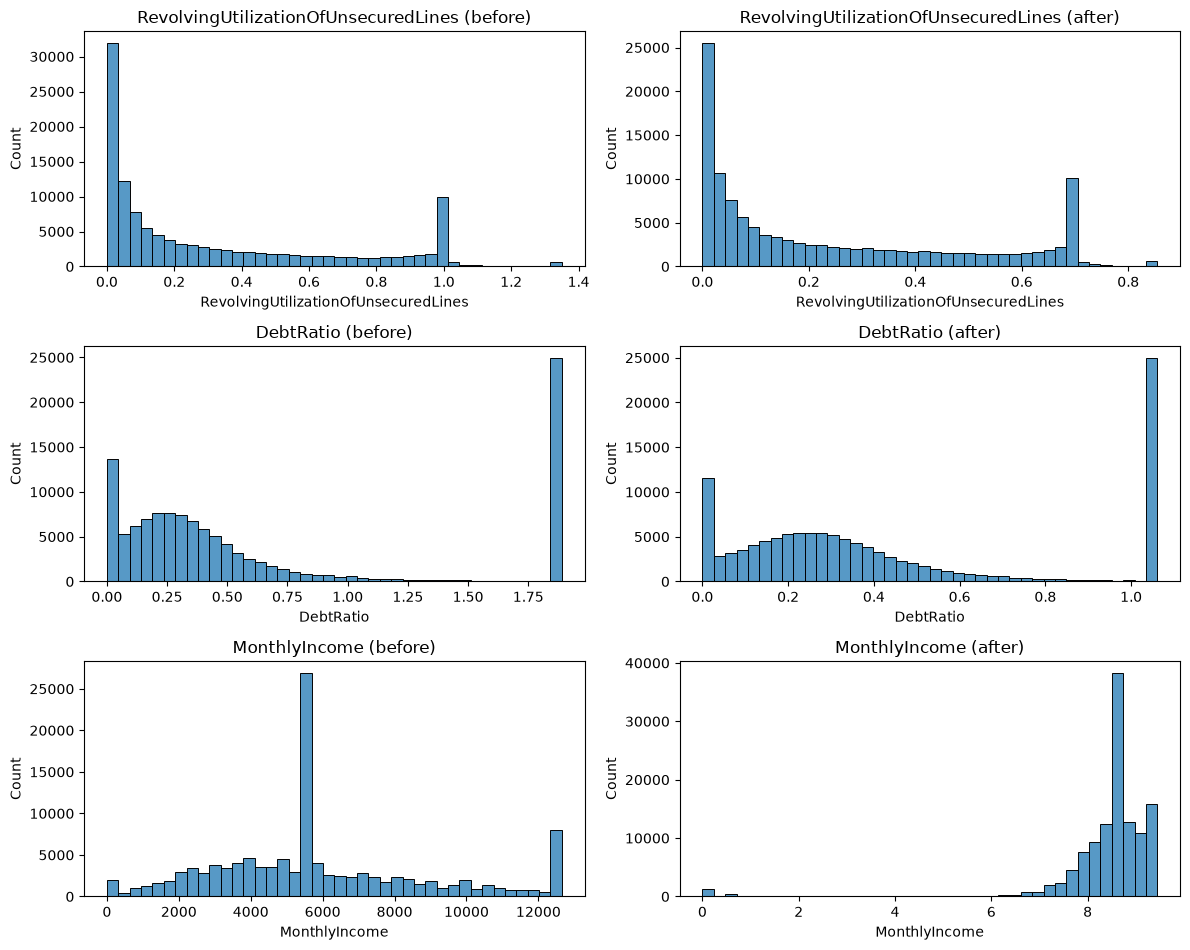

                                      before  after
RevolvingUtilizationOfUnsecuredLines    0.95   0.74
DebtRatio                               1.04   0.78
MonthlyIncome                           0.64  -5.29


In [18]:
log_cols = ['RevolvingUtilizationOfUnsecuredLines', 'DebtRatio',
            'MonthlyIncome']

def log_transform(df, cols=log_cols):
    df = df.copy()
    df[cols] = np.log1p(df[cols])
    return df

train_l = log_transform(train_f)
test_l = log_transform(test_f)


fig, axes = plt.subplots(len(log_cols), 2, figsize=(12, 3.2 * len(log_cols)))
for i, col in enumerate(log_cols):
    sns.histplot(train_f[col], ax=axes[i, 0], bins=40)
    axes[i, 0].set_title(f'{col} (before)')
    sns.histplot(train_l[col], ax=axes[i, 1], bins=40)
    axes[i, 1].set_title(f'{col} (after)')
plt.tight_layout()
plt.show()

skew_table = pd.DataFrame({'before': train_f[log_cols].skew(),
                           'after': train_l[log_cols].skew()}).round(2)
print(skew_table)

Log transform slightly reduced skew for RevolvingUtilizationOfUnsecuredLines and DebtRatio, which are  right-skewed. It worsened MonthlyIncome  which was only mildly skewed after capping.

In [19]:
train_l['MonthlyIncome']= np.expm1(train_l['MonthlyIncome'])
test_l['MonthlyIncome']= np.expm1(test_l['MonthlyIncome'])
print('MonthlyIncome skew after reverting:', round(train_l['MonthlyIncome'].skew(), 2))

MonthlyIncome skew after reverting: 0.64


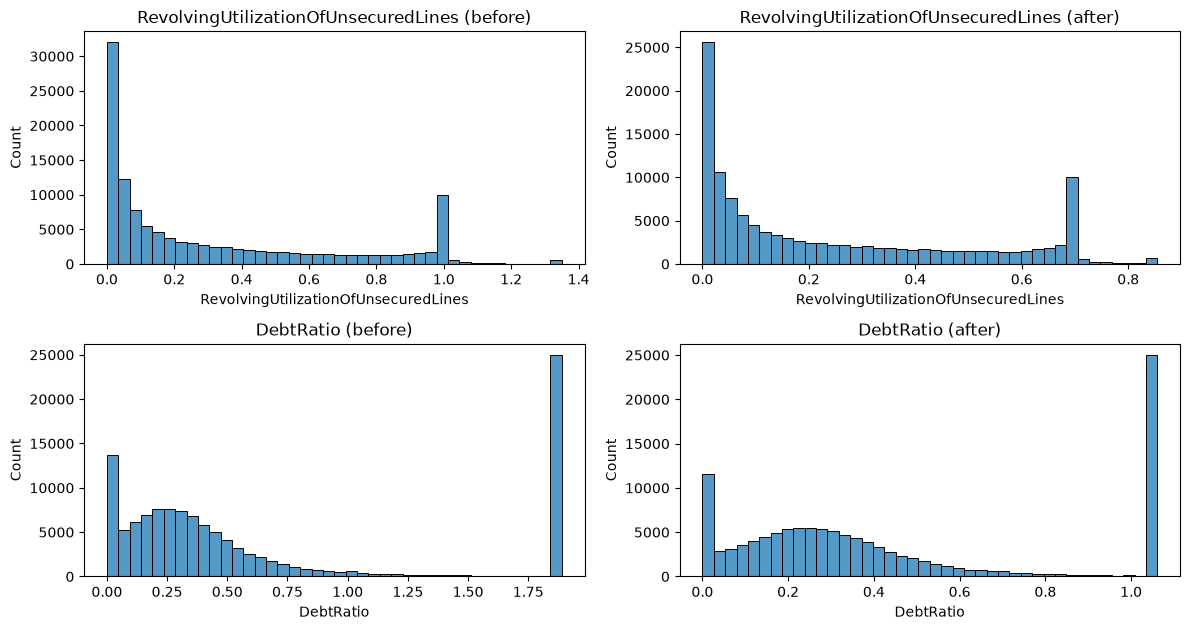

In [20]:
cols = ['RevolvingUtilizationOfUnsecuredLines', 'DebtRatio']

fig, axes = plt.subplots(len(cols), 2, figsize=(12, 3.2 * len(cols)))
for i, col in enumerate(cols):
    sns.histplot(train_f[col], ax=axes[i, 0], bins=40)
    axes[i, 0].set_title(f'{col} (before)')
    sns.histplot(train_l[col], ax=axes[i, 1], bins=40)
    axes[i, 1].set_title(f'{col} (after)')
plt.tight_layout()
plt.show()

`DebtRatio` becomes noticeably less skewed after the transform. `RevolvingUtilizationOfUnsecuredLines` changes much less, because its distribution has two groups (borrowers using almost none of their credit and borrowers close to or above their limit) and a log transform cannot remove that structure. Those high-utilization borrowers are real and informative, so they are kept.

## 7. Exploratory Data Analysis (training set only)

in classification boxplots are used by the target variable to answer a question, do either yes/no behave differently on each feature? if a feature shows no difference between the two groups, then it is no useful for prediction.

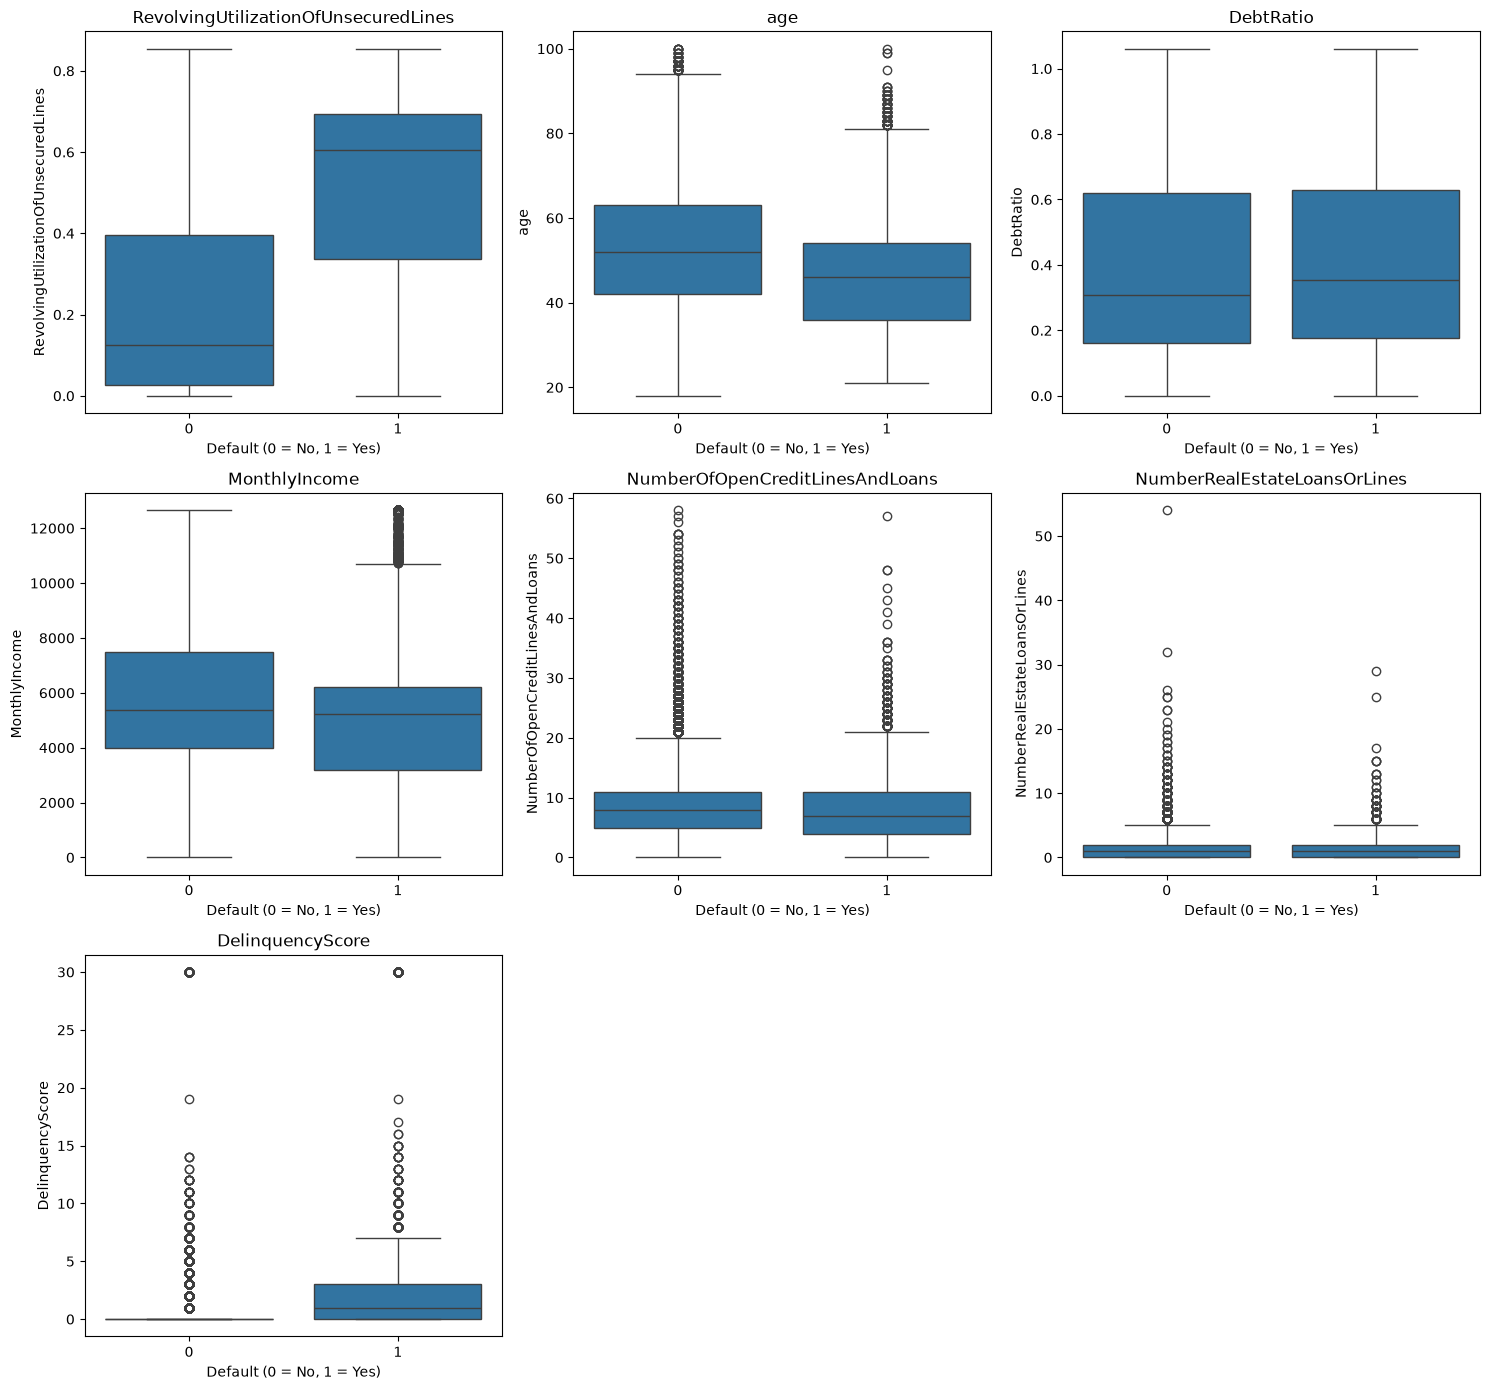

In [21]:
eda_features = ['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio', 'MonthlyIncome',
                'NumberOfOpenCreditLinesAndLoans', 'NumberRealEstateLoansOrLines',
                'DelinquencyScore']

fig, axes = plt.subplots(3, 3, figsize=(15, 14))
axes = axes.flatten()
for i, col in enumerate(eda_features):
    sns.boxplot(x= 'SeriousDlqin2yrs', y=col, data=train_l, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('Default (0 = No, 1 = Yes)')
for j in range(len(eda_features), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

### Features that separate the classes
- **RevolvingUtilizationOfUnsecuredLines:** The clearest separation. Defaulters have a median of about 0.6, against about 0.15 for non-defaulters, and their IQR (about 0.34-0.69) sits well above the non-defaulters' (about 0.03-0.40). Both classes reach the cap (about 0.85), so the capping is visible at the upper whisker.
- **DelinquencyScore:** Strong separation. Non-defaulters sit almost entirely at 0, while defaulters have a median of about 1, an IQR of about 0-3, and an upper whisker near 7. Both classes have outliers extending to 30, which looks like a ceiling or cap in this engineered feature(3x10).
- **age:** Defaulters tend to be younger (median about 46 vs about 52, IQR about 36-54 vs about 42-63). Both classes have high-age outliers up to 100.

### Features with weak or no separation
- **DebtRatio:** The distributions are very similar (median about 0.31 vs about 0.35, nearly identical IQRs), so it has limited standalone discriminative power. Both classes are capped at about 1.06.
- **MonthlyIncome (log scale):** Medians are close (about 5600 vs about 5500), with defaulters slightly lower. Both classes have many low-end outliers, including values near 0.
- **NumberOfOpenCreditLinesAndLoans:** Medians (about 8 vs about 7) and IQRs (about 5-11 vs about 4-11) are very similar. Both classes have a long upper tail reaching about 57-58, so this column appears uncapped.
- **NumberRealEstateLoansOrLines:** Nearly identical (median about 1, IQR about 0-2). Outliers reach 54 for non-defaulters and about 29 for defaulters, so this column also appears uncapped.

### Takeaways
- `RevolvingUtilizationOfUnsecuredLines`, `DelinquencyScore` and `age` look the most informative.

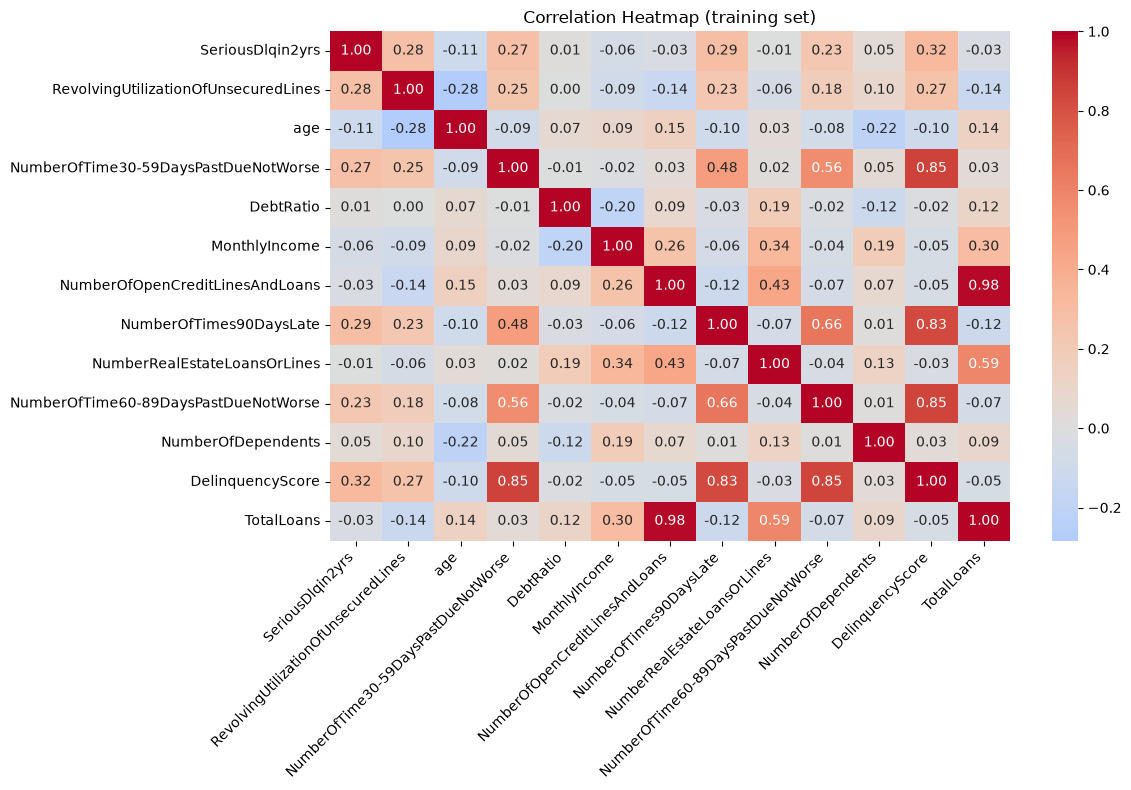

In [22]:
plt.figure(figsize=(12, 8))
sns.heatmap(train_l.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (training set)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 8. Feature Selection Based on Correlation

Highly correlated features carry the same information and may confuse the models.

- The three raw delinquency columns are fully captured by their sum, `DelinquencyScore`, so they are dropped.
- `TotalLoans` is almost perfectly correlated with `NumberOfOpenCreditLinesAndLoans` (about 0.98), so `TotalLoans` is dropped and the original column is kept.

In [23]:
DROP_COLS = delinq_cols + ['TotalLoans']

def select_features(df):
    return df.drop(columns=DROP_COLS)

In [24]:
train_final = select_features(train_l)
test_final = select_features(test_l)

x_train = train_final.drop(columns=['SeriousDlqin2yrs'])
y_train = train_final['SeriousDlqin2yrs']
x_test = test_final.drop(columns=['SeriousDlqin2yrs'])
y_test = test_final['SeriousDlqin2yrs']

print(x_train.columns.tolist())
print(x_train.shape, x_test.shape)

['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberRealEstateLoansOrLines', 'NumberOfDependents', 'DelinquencyScore']
(120000, 8) (30000, 8)


## 9. Handling Class Imbalance (SMOTE inside a pipeline)

SMOTE creates synthetic minority-class samples by interpolating between a defaulter and one of its nearest defaulter neighbours.

SMOTE and the scaler are placed **inside an `imblearn` Pipeline**. Two things follow from that:

1. The scaler and SMOTE are fit on training data only, and SMOTE is applied only when fitting, never when predicting. The test set is never resampled.
2. During cross-validation, SMOTE is applied to each fold's training portion only. If SMOTE were applied first and the resampled data were then cross-validated, synthetic copies of validation rows' neighbours would sit in the training folds and the cross-validation scores would look better than they really are.

## 10. Baseline Model Comparison

Three models are compared by crossvalidation on the training set using the default threshold of 0.5. Accuracy is deliberately left out: always predicting "no default" would score a high accuracy while catching no defaulters. The pipeline below scales and resamples the data as part of each cross-validation round, so these steps only ever see the training part of that round. Cross-validation trains the pipeline on 4 folds of the training data, then tests it on the fifth fold. Each of the folds becomes the testing fold in turn, and the results of each metric are then averaged to give the final results.

In [25]:
def make_pipeline(model): 
    return ImbPipeline(steps=[
        ('scaler', MinMaxScaler()),
        ('smote', SMOTE(random_state= 23)),
        ('model', model)
    ])

models = {
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'RandomForestClassifier': RandomForestClassifier(random_state=23),
    'XGBoost': XGBClassifier(random_state=23, eval_metric='logloss')
}
def cv_score_models(models, x_train, y_train):
    cv = StratifiedKFold(n_splits= 5 , shuffle=True, random_state=23)
    scoring = {
        'recall': 'recall',
        'precision': 'precision',
        'f1': 'f1',
        'roc_auc': 'roc_auc'
    }

    results = []
    for name, model in models.items():
        pipe = make_pipeline(model)
        scores = cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring)

        results.append({
            'Model': name,
            'Recall': scores['test_recall'].mean(),
            'Precision': scores['test_precision'].mean(),
            'F1': scores['test_f1'].mean(),
            'ROC_AUC': scores['test_roc_auc'].mean()
        })

    return pd.DataFrame(results).sort_values('ROC_AUC', ascending=False).round(4)

results_df = cv_score_models(models, x_train, y_train)
display(results_df)
for name, model in models.items():
    pipe = make_pipeline(model)
    pred = cross_val_predict(pipe, x_train, y_train, cv= StratifiedKFold(n_splits= 5 , shuffle=True, random_state=23))
    print(name)
    print(confusion_matrix(y_train, pred))
    print()

,Model,Recall,Precision,F1,ROC_AUC
0,LogisticRegression,0.7473,0.2099,0.3278,0.8522
2,XGBoost,0.2354,0.4813,0.3159,0.8501
1,RandomForestClassifier,0.2978,0.4327,0.3527,0.8317


LogisticRegression
[[89416 22563]
 [ 2027  5994]]

RandomForestClassifier
[[108843   3136]
 [  5632   2389]]

XGBoost
[[109947   2032]
 [  6133   1888]]



## Logistic Regression
According to the metrics, logistic regression had the highest recall of 0.7473, which means it catches most of the actual defaulters. However, it flags a lot of borrowers to do so, which lowers its precision to 0.2099, meaning only about 21% of the borrowers it flags are real defaulters. It had an F1 of 0.3278, which is low because the low precision drags it down, since F1 combines precision and recall. It had a ROC_AUC score of 0.8522, which means the model is good at ranking defaulters above non-defaulters across all thresholds.

According to the confusion matrix, the model correctly predicted 89,416 non-defaulters and correctly caught 5,994 defaulters. It wrongly flagged 22,563 non-defaulters as defaulters (false positives) and missed 2,027 actual defaulters by predicting them as non-defaulters (false negatives).

## Random Forest
According to the metrics, random forest had a recall of 0.2978, which means it misses most of the actual defaulters. However, it flags far fewer borrowers than logistic regression, which raises its precision to 0.4327, meaning about 43% of the borrowers it flags are real defaulters. It had an F1 of 0.3527, which is low because the low recall drags it down, since F1 combines precision and recall. It had a ROC_AUC score of 0.8317, which means the model is good at ranking defaulters above non-defaulters across all thresholds.

According to the confusion matrix, the model correctly predicted 108,843 non-defaulters and correctly caught 2,389 defaulters. It wrongly flagged 3,136 non-defaulters as defaulters (false positives) and missed 5,632 actual defaulters by predicting them as non-defaulters (false negatives).

## XGBoost
According to the metrics, XGBoost had a recall of 0.2354, which means it misses most of the actual defaulters. However, it flags far fewer borrowers than logistic regression, which raises its precision to 0.4813, meaning about 48% of the borrowers it flags are real defaulters. It had an F1 of 0.3159, which is low because the low recall drags it down, since F1 combines precision and recall. It had a ROC_AUC score of 0.8501, which means the model is good at ranking defaulters above non-defaulters across all thresholds.

According to the confusion matrix, the model correctly predicted 109,947 non-defaulters and correctly caught 1,888 defaulters. It wrongly flagged 2,032 non-defaulters as defaulters (false positives) and missed 6,133 actual defaulters by predicting them as non-defaulters (false negatives).

## 11. Hyperparameter Tuning 

Logistic Regression is tuned using grid search cv because of its fewer parameters while xgboost and randomforest are tuned using randomized search cv because of their numerous parameters.

In [26]:
lr_pipe = make_pipeline(LogisticRegression( max_iter=1000))

param_grid = {'model__C': [1, 10, 100, 1000, 10000, 100000]}

lr_grid = GridSearchCV(lr_pipe, param_grid, cv= StratifiedKFold(n_splits=5, shuffle=True, random_state=23) , scoring='roc_auc', n_jobs=-1)
lr_grid.fit(x_train, y_train)

print('Best params:', lr_grid.best_params_)
print('Best CV ROC-AUC:', round(lr_grid.best_score_, 4))

Best params: {'model__C': 10000}
Best CV ROC-AUC: 0.8526


In [27]:
res = pd.DataFrame(lr_grid.cv_results_)[['param_model__C', 'mean_test_score']]
print(res.sort_values('mean_test_score', ascending=False).round(4))

   param_model__C  mean_test_score
4           10000           0.8526
5          100000           0.8526
3            1000           0.8526
2             100           0.8526
1              10           0.8525
0               1           0.8522


tuning C made no meaningful difference (CV ROC AUC 0.8509 to 0.8513), so a moderate C=10 was chosen.

In [28]:
lr_final = make_pipeline(LogisticRegression(C=10, max_iter=1000))

In [29]:
xg_pipe = make_pipeline(XGBClassifier(random_state=23, eval_metric='logloss'))

xg_params = {
    'model__n_estimators': [100, 300, 500, 1000],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'model__max_depth': [3, 4, 6, 8, 10],
    'model__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0]
}

xg_random = RandomizedSearchCV(
    estimator=xg_pipe,
    param_distributions=xg_params,
    n_iter=15,  # Number of parameter settings sampled
    cv= StratifiedKFold(n_splits= 5 , shuffle=True, random_state=23),
    scoring='roc_auc',
    n_jobs=-1,
    random_state=23,verbose = 2
)


xg_random.fit(x_train, y_train)

print('Best XGB params:', xg_random.best_params_)
print('Best XGB CV ROC-AUC:', round(xg_random.best_score_, 4))


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best XGB params: {'model__subsample': 0.9, 'model__n_estimators': 500, 'model__max_depth': 4, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.7}
Best XGB CV ROC-AUC: 0.8579


In [30]:
rf_pipe = make_pipeline(RandomForestClassifier(random_state=23))


rf_params = {
    'model__n_estimators': [100, 200, 300,350,450,500],
    'model__max_depth': [8, 12, 16, 20],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__max_features': ['sqrt', 0.5]
}

rf_random = RandomizedSearchCV(
    rf_pipe, rf_params, n_iter=15, cv= StratifiedKFold(n_splits= 5 , shuffle=True, random_state=23),
    scoring='roc_auc', n_jobs=-2, random_state=23, verbose=2
)


rf_random.fit(x_train, y_train)
print('Best RF params:', rf_random.best_params_)
print('Best RF CV ROC-AUC:', round(rf_random.best_score_, 4))


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best RF params: {'model__n_estimators': 100, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': 8}
Best RF CV ROC-AUC: 0.8573


After performing hyperparameter tuning on the models, Xgboost had the highest ROC-AUC of 0.8579 which is slightly higher than Random Forest(0.8573) 

## 12. Choosing the Decision Threshold (on out-of-fold training predictions)

The model outputs a probability of default, and a threshold turns it into a yes/no decision. The default of 0.5 is not tied to any business goal.

The threshold is chosen using **out-of-fold predictions on the training set**, so the test set stays untouched.
- **A recall target**: the highest threshold that still catches at least `RECALL_TARGET` of real defaulters. This is the final choice, since missing a defaulter costs the lender more than a false alarm.


In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)

tuned_pipes = {
    'LogisticRegression': make_pipeline(LogisticRegression(C=10, max_iter=1000)),
    'RandomForest': rf_random.best_estimator_,
    'XGBoost': xg_random.best_estimator_,
}

oof_proba = {}
for name, pipe in tuned_pipes.items():
    oof_proba[name] = cross_val_predict(pipe, x_train, y_train, cv=cv,
                                        method='predict_proba',n_jobs= -2, verbose = 2 )[:, 1]

[Parallel(n_jobs=-2)]: Using backend LokyBackend with 7 concurrent workers.
[Parallel(n_jobs=-2)]: Done   5 out of   5 | elapsed:    2.1s finished
[Parallel(n_jobs=-2)]: Using backend LokyBackend with 7 concurrent workers.
[Parallel(n_jobs=-2)]: Done   5 out of   5 | elapsed:  1.5min finished
[Parallel(n_jobs=-2)]: Using backend LokyBackend with 7 concurrent workers.
[Parallel(n_jobs=-2)]: Done   5 out of   5 | elapsed:   23.4s finished


In [32]:
RECALL_TARGET = 0.80
final_thresholds = {}

for name, proba in oof_proba.items():
    precision_c, recall_c, pr_thresholds = precision_recall_curve(y_train, proba)
    meets_target = recall_c[:-1] >= RECALL_TARGET
    FINAL_THRESHOLD = float(pr_thresholds[meets_target].max())
    final_thresholds[name] = FINAL_THRESHOLD
    print(name)

    rows = []
    for t in [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, round(FINAL_THRESHOLD, 3)]:
        pred_t = (proba >= t).astype(int)
        rows.append({'threshold': t,
                     'recall': recall_score(y_train, pred_t),
                     'precision': precision_score(y_train, pred_t, zero_division=0),
                     'f1': f1_score(y_train, pred_t)})
    display(pd.DataFrame(rows).drop_duplicates('threshold').sort_values('threshold').round(3))

LogisticRegression


,threshold,recall,precision,f1
0,0.200,0.953,0.102,0.184
1,0.250,0.923,0.121,0.214
2,0.300,0.890,0.137,0.237
3,0.350,0.858,0.153,0.260
4,0.400,0.824,0.170,0.282
9,0.432,0.800,0.182,0.297
5,0.450,0.787,0.189,0.305
6,0.500,0.745,0.211,0.329
7,0.550,0.696,0.237,0.354
8,0.600,0.639,0.268,0.378


RandomForest


,threshold,recall,precision,f1
0,0.200,0.856,0.160,0.269
1,0.250,0.802,0.186,0.302
9,0.251,0.800,0.187,0.303
2,0.300,0.747,0.217,0.336
3,0.350,0.701,0.247,0.366
4,0.400,0.654,0.278,0.390
5,0.450,0.611,0.306,0.408
6,0.500,0.574,0.327,0.417
7,0.550,0.540,0.350,0.425
8,0.600,0.508,0.374,0.431


XGBoost


,threshold,recall,precision,f1
0,0.200,0.857,0.160,0.270
1,0.250,0.803,0.188,0.305
9,0.254,0.799,0.191,0.308
2,0.300,0.747,0.219,0.338
3,0.350,0.695,0.248,0.366
4,0.400,0.638,0.284,0.393
5,0.450,0.590,0.322,0.416
6,0.500,0.548,0.351,0.428
7,0.550,0.501,0.380,0.432
8,0.600,0.455,0.407,0.430


According to the results of the threshold tuning, all three models were tuned to the same recall target (0.80), so their recall is about equal by design. At that target XGBoost had the highest precision (0.191) and F1 (0.308), although the differences from random forest (0.187, 0.303) and logistic regression (0.182, 0.297) are very small. XGBoost reached the target at a threshold of 0.254, which means it flags a borrower as a defaulter when their predicted probability of default is 0.254 or higher.

## 13. Final Evaluation on the Test Set

This is the first and only time the tuned model and the chosen threshold are evaluated on the test set.

In [33]:
final_pipe = xg_random.best_estimator_
test_proba = final_pipe.predict_proba(x_test)[:, 1]
test_pred = (test_proba >= final_thresholds['XGBoost']).astype(int)

print('Recall:',round( recall_score(y_test, test_pred),4))
print('Precision:', round(precision_score(y_test, test_pred),4))
print('F1:', round(f1_score(y_test, test_pred),4))
print('ROC AUC:',round( roc_auc_score(y_test, test_proba),4))
print(confusion_matrix(y_test, test_pred))

Recall: 0.816
Precision: 0.1942
F1: 0.3137
ROC AUC: 0.8615
[[21207  6788]
 [  369  1636]]


After testing XGBoost on the test set with the chosen threshold of 0.254, it had a recall of 0.816, which means it caught about 82% of the actual defaulters, but it flags a lot of borrowers to do so. Its precision was 0.1942, meaning only about 19% of the borrowers it flags are real defaulters. This is the cost of aiming for high recall: lowering the threshold catches more defaulters but also flags more good borrowers. It had an F1 of 0.3137, which is low because the low precision drags it down, since F1 combines precision and recall. It had a ROC_AUC score of 0.8615, which means the model is good at ranking defaulters above non-defaulters across all thresholds.

According to the confusion matrix, the model correctly predicted 21,207 non-defaulters and correctly caught 1,636 defaulters. It wrongly flagged 6,788 non-defaulters as defaulters (false positives) and missed 369 actual defaulters by predicting them as non-defaulters (false negatives). In total it flagged 8,424 borrowers (about 28% of the test set) to catch those 1,636 defaulters.



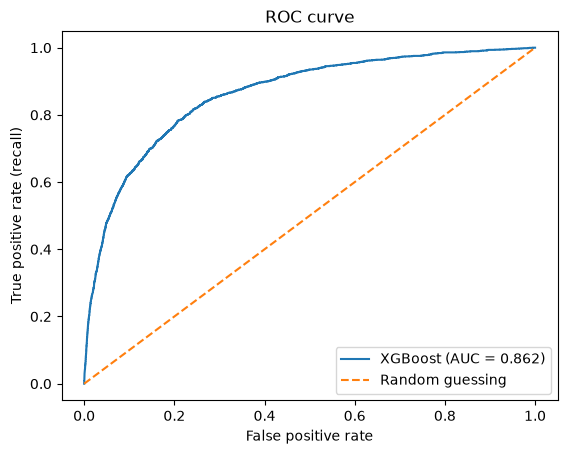

In [39]:
fpr, tpr, _ = roc_curve(y_test, test_proba)

plt.plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc_score(y_test, test_proba):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--',label='Random guessing')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('ROC curve')
plt.legend()
plt.show()

## ROC Curve
The ROC curve of the XGBoost model on the test set lies well above the random-guessing diagonal, with an AUC of 0.860, meaning the model ranks a random defaulter above a random non-defaulter about 86% of the time.

## 14. Feature Importance

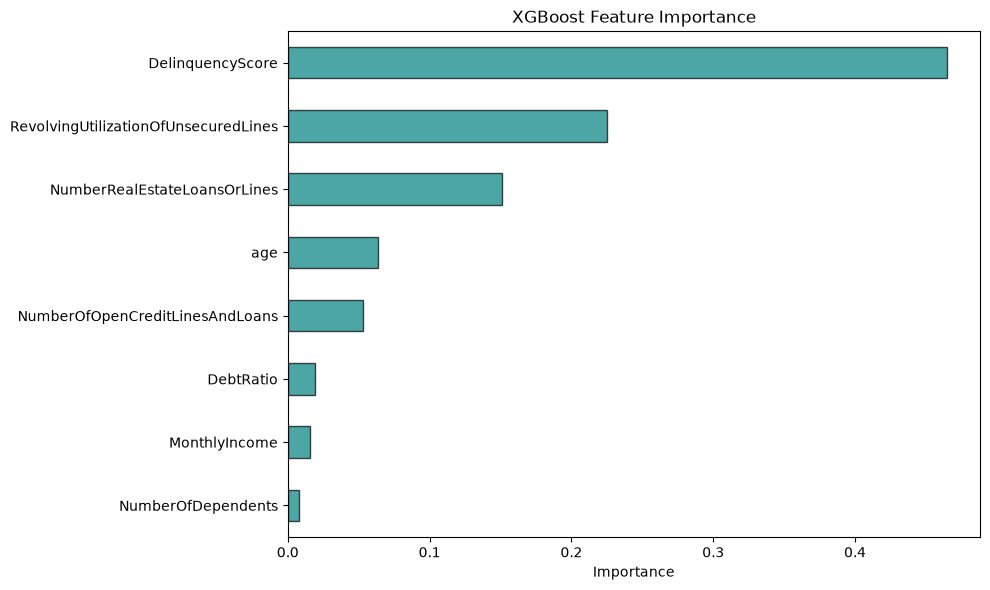

In [35]:
best_xgb = xg_random.best_estimator_.named_steps['model']

importances = pd.Series(best_xgb.feature_importances_, index=x_train.columns).sort_values()

plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='teal', edgecolor='black', alpha=0.7)
plt.xlabel('Importance')
plt.title('XGBoost Feature Importance')
plt.tight_layout()
plt.show()

The bar plot above shows the features with the most importance to the model's
predictions. The most important feature was `Delinquencyscore` (Sum of the three past-due counts), which influences the model's prediction more than any other feature.

## 15. Save the Model

The trained model, the decision threshold and the feature columns are saved together in one file (`loan_model.pkl`). The model is the full pipeline: the scaler, SMOTE and the tuned XGBoost classifier. SMOTE is only applied during training and is skipped at prediction time. The threshold is the cut-off for turning probabilities into decisions, so a borrower whose predicted probability is at or above it is flagged as a defaulter. The feature columns record the column names and their training order, so new data can be arranged the same way before prediction.

The cleaning steps done before the pipeline  are not part of this file, so new data must go through the same steps before it is passed to the model.

In [36]:
import joblib

joblib.dump({'model': xg_random.best_estimator_,
             'threshold': final_thresholds['XGBoost'],
             'feature_columns': list(x_train.columns)},
            'loan_model.pkl')

['loan_model.pkl']

## 16. Conclusion

This project built a leak-free classification pipeline for predicting loan default on the "Give Me Some Credit" dataset. The data was split first, all cleaning parameters were learned from the training set, and SMOTE and scaling were placed inside the cross-validation pipeline so that no information from validation or test data influenced training.

Delinquency history and credit utilization are the strongest drivers of default risk; the three raw late-payment columns were combined into a single `DelinquencyScore` and the near-duplicate `TotalLoans` column was dropped to remove redundancy.

XGBoost was chosen as the final model because of its performance even though it was close to both random forest and Logistic regression.
**Final test-set results:** Recall: 0.816, Precision: 0.1942, F1: 0.3137, ROC AUC: 0.8615, and a confusion matrix of 21,207 (true negatives), 1,636 (true positives), 6,788 (false positives) and 369 (false negatives).
**Limitations**
- Precision is low at a recall-focused threshold, so many safe borrowers are flagged for review.
- The threshold was chosen for a hypothetical cost tradeoff; a real lender would set it from actual loan-loss and review costs.